<a href="https://colab.research.google.com/github/shreyachow/myproject/blob/main/population-inference/gwtc4_population.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Spectral Siren Population Inference on GWTC-4

The fourth gravitational-wave transient catalog [GWTC-4](https://arxiv.org/pdf/2508.18082) includes all compact binary coalescences observed during Advanced LIGO/Virgo's first three oberving runs.

"Spectral siren" cosmology (see, e.g., [Ezquiaga & Holz](https://arxiv.org/abs/2202.08240)) uses features in the black hole mass spectrum to constrain the distance-redshift relation.

`GWPopulation` builds upon [`Bilby`](git.ligo.org/lscsoft/bilby) ([Talbot _et al._ (2025)](https://joss.theoj.org/papers/10.21105/joss.07753)) to provide simple, modular, user-friendly, population inference.
`wcosmo` provides optimized cosmology functionality for `GWPopulation`.

There are many [implemented models](https://colmtalbot.github.io/gwpopulation/_autosummary/gwpopulation.models.html#module-gwpopulation.models) and an example of defining custom models is included below.
In this example we use:

- A mass distribution in primary mass and mass ratio from Talbot & Thrane (2018) ([arXiv:1801:02699](https://arxiv.org/abs/1801.02699)). This is equivalent to the `PowerLaw + Peak` model used in LVK analyses without the low-mass smoothing for computational efficiency.
- Half-Gaussian + isotropic spin tilt distribution from Talbot & Thrane (2017) ([arXiv:1704.08370](https://arxiv.org/abs/1704.08370)).
- A truncated Gaussian distribution as used in[arXiv:2508.18082](https://arxiv.org/pdf/2508.18082).
- Redshift evolution model as in Fishbach+ (2018) ([arXiv:1805.10270](https://arxiv.org/abs/1805.10270)).
- A variable Flat Lambda CDM cosmology using a modified version of the approximation in [arXiv:1111.6396](https://arxiv.org/abs/1111.6396) as implemented in `wcosmo`.

For more information on `GWPopulation` see the [git repository](https://github.com/ColmTalbot/gwpopulation), [documentation](https://colmtalbot.github.io/gwpopulation/).


## Setup

If you're using colab.research.google.com you will want to choose a GPU-accelerated runtime (I'm going to use a T4 GPU).

"runtime"->"change runtime type"->"Hardware accelerator = GPU"

## Install some needed packages

All of the packages we need for this notebook other than `GWPopulation` (and it's dependencies) are already installed in Google colab, so we just need the following installation command.

In [1]:
!pip install gwpopulation

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.4/6.4 MB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 113.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 780.0/780.0 kB 65.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 78.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.9/102.9 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.4/47.4 kB 5.8 MB/s eta 0:00:00


## Imports

Import the packages required for the script.
We also set the backend for array operations to `jax` which allows us to take advantage of just-in-time (jit) compilation in addition to GPU-parallelisation when available.

In [2]:
import bilby as bb
import gwpopulation as gwpop
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from bilby.core.prior import PriorDict, Uniform
from gwpopulation.experimental.cosmo_models import CosmoModel
from gwpopulation.experimental.jax import JittedLikelihood
from wcosmo import disable_units, Planck15

disable_units()
gwpop.set_backend("jax")

xp = gwpop.utils.xp

%matplotlib inline

## Load data

We're using the posteriors and sensitivity injections from the GWTC-4 data release in a pre-processed format.

These files were produced by [`gwpopulation-pipe`](https://docs.ligo.org/ratesAndPopulations/gwpopulation_pipe) to reduce the many GB of posterior sample files to a pair of ~100Mb files.

This file includes all of the confidently identified binary black hole mergers and no potentially neutron star containing binaries.

We also need to modify some of the stored parameters as we are going to include a cosmological fit so we will fit detector frame masses and luminosity distance.

The data files can be found [here](https://drive.google.com/drive/folders/1wyfR6sYvYVdBefF9_vrVTp0Btu03OlzL?usp=sharing).
The original data can be found at [zenodo:5546663](https://zenodo.org/records/5546663), [zenodo:6513631](https://zenodo.org/records/6513631), and [zenodo:16053484](https://zenodo.org/records/16053484) along with citation information and the sensitivity injections are available at[zenodo:16740128](https://zenodo.org/records/16740128).

In [3]:
!gdown https://drive.google.com/uc?id=1qkhkXD1Y_tm-YW74CuklcfiBkorJ0OLi
!gdown https://drive.google.com/uc?id=1nmXFr_yVcxVWO4D6c3cs8y1M7JgSFzDo

Downloading...
From: https://drive.google.com/uc?id=1qkhkXD1Y_tm-YW74CuklcfiBkorJ0OLi
To: /content/gwtc4_injections_dict.pkl
100% 68.2M/68.2M [00:00<00:00, 172MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1nmXFr_yVcxVWO4D6c3cs8y1M7JgSFzDo
From (redirected): https://drive.google.com/uc?id=1nmXFr_yVcxVWO4D6c3cs8y1M7JgSFzDo&confirm=t&uuid=031c1233-5585-4ac2-9340-489c420f2590
To: /content/gwtc4_posteriors.pkl
100% 415M/415M [00:02<00:00, 171MB/s]


In [4]:
posteriors = pd.read_pickle("gwtc4_posteriors.pkl")
data = pd.read_pickle("gwtc4_injections_dict.pkl")

for post in posteriors:
    post["luminosity_distance"] = Planck15.luminosity_distance(post["redshift"])
    post["mass_1_detector"] = post.pop("mass_1") * (1 + post["redshift"])
    post["prior"] /= Planck15.dDLdz(post["redshift"]) * (1 + post["redshift"])
    del post["redshift"]

data["luminosity_distance"] = Planck15.luminosity_distance(data["redshift"])
data["mass_1_detector"] = data.pop("mass_1") * (1 + data["redshift"])
data["prior"] /= Planck15.dDLdz(data["redshift"]) * (1 + data["redshift"])
del data["redshift"]

Let's make some plots to visualize the data.

We will include in all the plots both the found injections and the per-event posteriors.
We should expect the found injections to fully cover the per-event posterior samples to ensure reliable population inference.

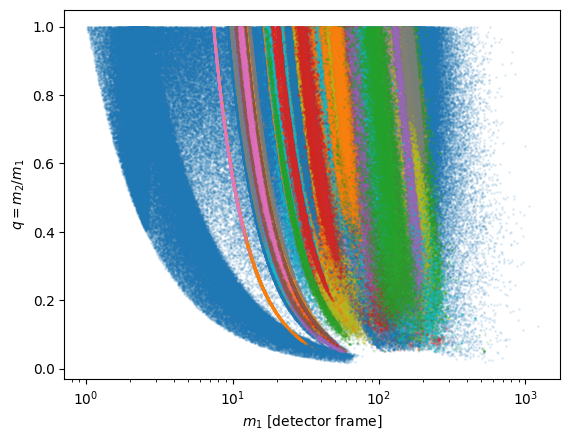

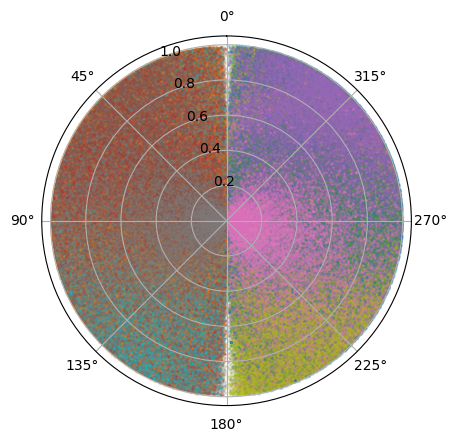

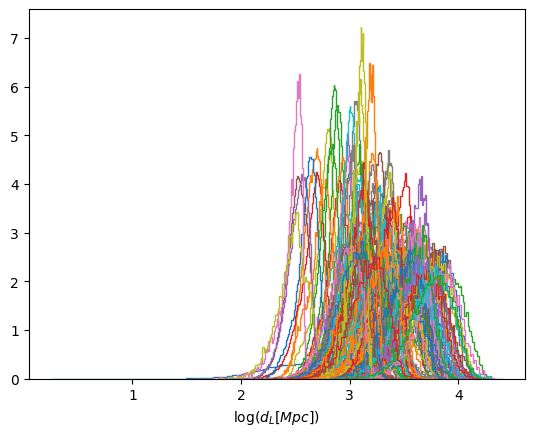

In [5]:
plt.scatter(data["mass_1_detector"], data["mass_ratio"], s=1, alpha=0.1)

for post in posteriors:
    plt.scatter(post["mass_1_detector"], post["mass_ratio"], s=1, alpha=0.1)
plt.xscale("log")
plt.xlabel("$m_1$ [detector frame]")
plt.ylabel("$q = m_2 / m_1$")
plt.show()
plt.close()

fig, ax = plt.subplots(subplot_kw={"projection": "polar"})
plt.scatter(
    -np.arccos(data["cos_tilt_1"]),
    data["a_1"],
    s=1,
    alpha=0.1,
)
plt.scatter(
    np.arccos(data["cos_tilt_2"]),
    data["a_2"],
    s=1,
    alpha=0.1,
)

for post in posteriors:
    plt.scatter(
        -np.arccos(post["cos_tilt_1"]),
        post["a_1"],
        s=1,
        alpha=0.1,
    )
    plt.scatter(
        np.arccos(post["cos_tilt_2"]),
        post["a_2"],
        s=1,
        alpha=0.1,
    )
ax.set_theta_offset(np.pi / 2)

plt.show()
plt.close()

plt.hist(np.log10(data["luminosity_distance"]), bins=100, density=True, histtype="step")

for post in posteriors:
    plt.hist(np.log10(post["luminosity_distance"]), bins=100, density=True, histtype="step")
plt.xlabel("$\\log(d_L [Mpc])$")
plt.show()
plt.close()

## Define some models and the likelihood

We need to define `Bilby` `Model` objects for the numerator and denominator independently as these cache some computations interally.

Note that we are using a [`CosmoModel`](https://colmtalbot.github.io/gwpopulation/autoapi/gwpopulation/experimental/cosmo_models/index.html#gwpopulation.experimental.cosmo_models.CosmoModel), this in an experimental feature and so the specific API may change in future, but the basic funcionality should be stable.
We create a model that can infer the three parameters of [`wCDM`](https://wcosmo.readthedocs.io/en/latest/api/_autosummary/wcosmo.astropy.FlatwCDM.html).

The [`HyperparameterLikelihood`](https://colmtalbot.github.io/gwpopulation/autoapi/gwpopulation/hyperpe/index.html#gwpopulation.hyperpe.HyperparameterLikelihood) is equivalent to marginalising over the local merger rate, with a uniform-in-log prior.
The posterior for the merger rate can be recovered in post-processing.

We provide:
- `posteriors`: a list of `pandas` DataFrames.
- `hyper_prior`: our population model, as defined above.
- `selection_function`: anything which evaluates the selection function.

We can also provide:
- `conversion_function`: this converts between the parameters we sample in and those needed by the model, e.g., for sampling in the mean and variance of the beta distribution.
- `max_samples`: the maximum number of samples to use from each posterior, this defaults to the length of the shortest posterior.

### Define a custom spin model

The base model for spin magnitudes used in GWTC-4 isn't available in `GWPopulation` directly.
However, defining new models is straightforward!

The most important thing to match is the expected function signature.
`GWPopulation` performs introspection on the function to determine which variables to pass to each model.
- The first argument must be called `dataset` and should be a dictionary with keys given by the parameters to fit.
- The remaining arguments are the names of the population parameters.
- The function should return an array containing the model evaluated at each of the points in `dataset`.

Since a truncated normal is a standard building block for population models, we can use the version shipped with `GWPopulation`.

In [6]:
from gwpopulation.utils import powerlaw, truncnorm


def truncated_normal_spin_magnitude(
    dataset: dict[str, xp.ndarray],
    mu_chi: float,
    sigma_chi: float,
    amax: float,
) -> xp.ndarray:
    kwargs = dict(mu=mu_chi, sigma=sigma_chi, low=0, high=amax)
    return (
        truncnorm(dataset["a_1"], **kwargs)
        * truncnorm(dataset["a_2"], **kwargs)
    )

In [7]:
model = CosmoModel(
    model_functions=[
        gwpop.models.mass.two_component_primary_mass_ratio,
        truncated_normal_spin_magnitude,
        gwpop.models.spin.iid_spin_orientation_gaussian_isotropic,
        gwpop.models.redshift.PowerLawRedshift(cosmo_model="FlatwCDM"),
    ],
    cosmo_model="FlatwCDM",
)

vt = gwpop.vt.ResamplingVT(model=model, data=data, n_events=len(posteriors))

likelihood = gwpop.hyperpe.HyperparameterLikelihood(
    posteriors=posteriors,
    hyper_prior=model,
    selection_function=vt,
)

## Define our prior

The mass model has eight parameters that we vary that are described in arXiv:1801:02699. This model is sometimes referred to as "PowerLaw+Peak"

The spin magnitude model is a normal distribution with the usual parameterization, and the spin orientation model is a mixure of a uniform component and a truncated Gaussian that peaks at aligned spin. This combination is sometimes referred to as "Default".

For redshift we use a model that looks like

$$p(z) \propto \frac{d V_{c}}{dz} (1 + z)^{λ - 1}$$

Finally, we set priors on the three parameters of the `wCDM` model, `H0` (the Hubble constant), `Omega_{m0}` (the matter fraction of the Universe at current time), `w0` (the constant dark energy equation of state).

In [8]:
priors = PriorDict()

# mass
priors["alpha"] = Uniform(minimum=-2, maximum=4, latex_label="$\\alpha$")
priors["beta"] = Uniform(minimum=-4, maximum=12, latex_label="$\\beta$")
priors["mmin"] = Uniform(minimum=2, maximum=10, latex_label="$m_{\\min}$")
priors["mmax"] = Uniform(minimum=150, maximum=400, latex_label="$m_{\\max}$")
priors["lam"] = Uniform(minimum=0, maximum=1, latex_label="$\\lambda_{m}$")
priors["mpp"] = Uniform(minimum=5, maximum=50, latex_label="$\\mu_{m}$")
priors["sigpp"] = Uniform(minimum=1, maximum=10, latex_label="$\\sigma_{m}$")
priors["gaussian_mass_maximum"] = Uniform(minimum=100, maximum=200, latex_label="$\\max_{g}$")
# spin
priors["amax"] = Uniform(minimum=0.5, maximum=1.0, latex_label="$a_{\\max}$")
priors["mu_chi"] = Uniform(
    minimum=-1, maximum=1, latex_label="$\\mu_{\\chi}$"
)
priors["sigma_chi"] = Uniform(minimum=0.05, maximum=2, latex_label="$\\sigma_{\\chi}$")
priors["mu_spin"] = Uniform(minimum=-1, maximum=1, latex_label="$\\mu$")
priors["xi_spin"] = Uniform(minimum=0, maximum=1, latex_label="$\\xi$")
priors["sigma_spin"] = Uniform(minimum=0.3, maximum=4, latex_label="$\\sigma$")

priors["H0"] = Uniform(minimum=20, maximum=200, latex_label="$H_0$")
priors["Om0"] = Uniform(minimum=0, maximum=1, latex_label="$\\Omega_{m,0}$")
priors["w0"] = Uniform(minimum=-1.5, maximum=-0.5, latex_label="$w_{0}$")
priors["lamb"] = Uniform(minimum=-1, maximum=10, latex_label="$\\lambda_{z}$")

## Just-in-time compile

We JIT compile the likelihood object before starting the sampler.
This is done using the `gwpopulation.experimental.jax.JittedLikelihood` class.

We then time the original likelihood object and the JIT-ed version.
Note that we do two evaluations for each object as the first evaluation must compile the likelihood and so takes longer. (In addition to the JIT compilation, `JAX` compiles GPU functionality at the first evaluation, but this is less extreme than the full JIT compilation.)

In [9]:
parameters = priors.sample()
likelihood.log_likelihood_ratio(parameters)
%time print(likelihood.log_likelihood_ratio(parameters))
jit_likelihood = JittedLikelihood(likelihood)
%time print(jit_likelihood.log_likelihood_ratio(parameters))
%time print(jit_likelihood.log_likelihood_ratio(parameters))

-1.7976931348623157e+308
CPU times: user 740 ms, sys: 194 ms, total: 934 ms
Wall time: 662 ms
-1.7976931348623157e+308
CPU times: user 16.7 s, sys: 1.08 s, total: 17.8 s
Wall time: 16.5 s
-1.7976931348623157e+308
CPU times: user 38.5 ms, sys: 966 µs, total: 39.5 ms
Wall time: 67.6 ms


## Run the sampler

We'll use the sampler `dynesty` and use a small number of live points to reduce the runtime (total runtime should be approximately 25 minutes on T4 GPUs via Google colab, on the A100 available with a Colab Pro subscription, this will be faster).
The settings here may not give publication quality results, a convergence test should be performed before making strong quantitative statements.

`bilby` times a single likelihood evaluation before beginning the run, however, this isn't well defined with JAX.

**Note:** sometimes this finds a high likelihood mode, likely due to [breakdowns in the approximation](https://arxiv.org/abs/2304.06138) used to estimate the likelihood. If you see `dlogz > -700`, you should interrupt the execution and restart.

In [10]:
result = bb.run_sampler(
    likelihood=jit_likelihood,
    priors=priors,
    sampler="dynesty",
    nlive=100,
    label="cosmo",
    sample="acceptance-walk",
    verbose=True,
    naccept=5,
    resume=False,
    save="hdf5",
)

10:54 bilby INFO    : Running for label 'cosmo', output will be saved to 'outdir'
10:54 bilby INFO    : Analysis priors:
10:54 bilby INFO    : alpha=Uniform(minimum=-2, maximum=4, name=None, latex_label='$\\alpha$', unit=None, boundary=None)
10:54 bilby INFO    : beta=Uniform(minimum=-4, maximum=12, name=None, latex_label='$\\beta$', unit=None, boundary=None)
10:54 bilby INFO    : mmin=Uniform(minimum=2, maximum=10, name=None, latex_label='$m_{\\min}$', unit=None, boundary=None)
10:54 bilby INFO    : mmax=Uniform(minimum=150, maximum=400, name=None, latex_label='$m_{\\max}$', unit=None, boundary=None)
10:54 bilby INFO    : lam=Uniform(minimum=0, maximum=1, name=None, latex_label='$\\lambda_{m}$', unit=None, boundary=None)
10:54 bilby INFO    : mpp=Uniform(minimum=5, maximum=50, name=None, latex_label='$\\mu_{m}$', unit=None, boundary=None)
10:54 bilby INFO    : sigpp=Uniform(minimum=1, maximum=10, name=None, latex_label='$\\sigma_{m}$', unit=None, boundary=None)
10:54 bilby INFO    : g

1it [00:00, ?it/s]

11:19 bilby INFO    : Written checkpoint file outdir/cosmo_resume.pickle
11:19 bilby INFO    : Written checkpoint file outdir/cosmo_resume.pickle
11:19 bilby INFO    : Rejection sampling nested samples to obtain 824 posterior samples
11:19 bilby INFO    : Sampling time: 0:24:18.653007
11:19 bilby INFO    : Summary of results:
nsamples: 824
ln_noise_evidence:    nan
ln_evidence:    nan +/-  0.495
ln_bayes_factor: -713.899 +/-  0.495



## Plot some posteriors

We can look at the posteriors on some of the parameters, here the cosmology parameters and the location of the mass peak and the redshift evolution.

We see that the value of the Hubble constant is strongly correlated with the location of the peak in the mass distribution as has been noted elsewhere.

We also include the values of the cosmology parameters reported in the `Planck15` cosmology for reference.

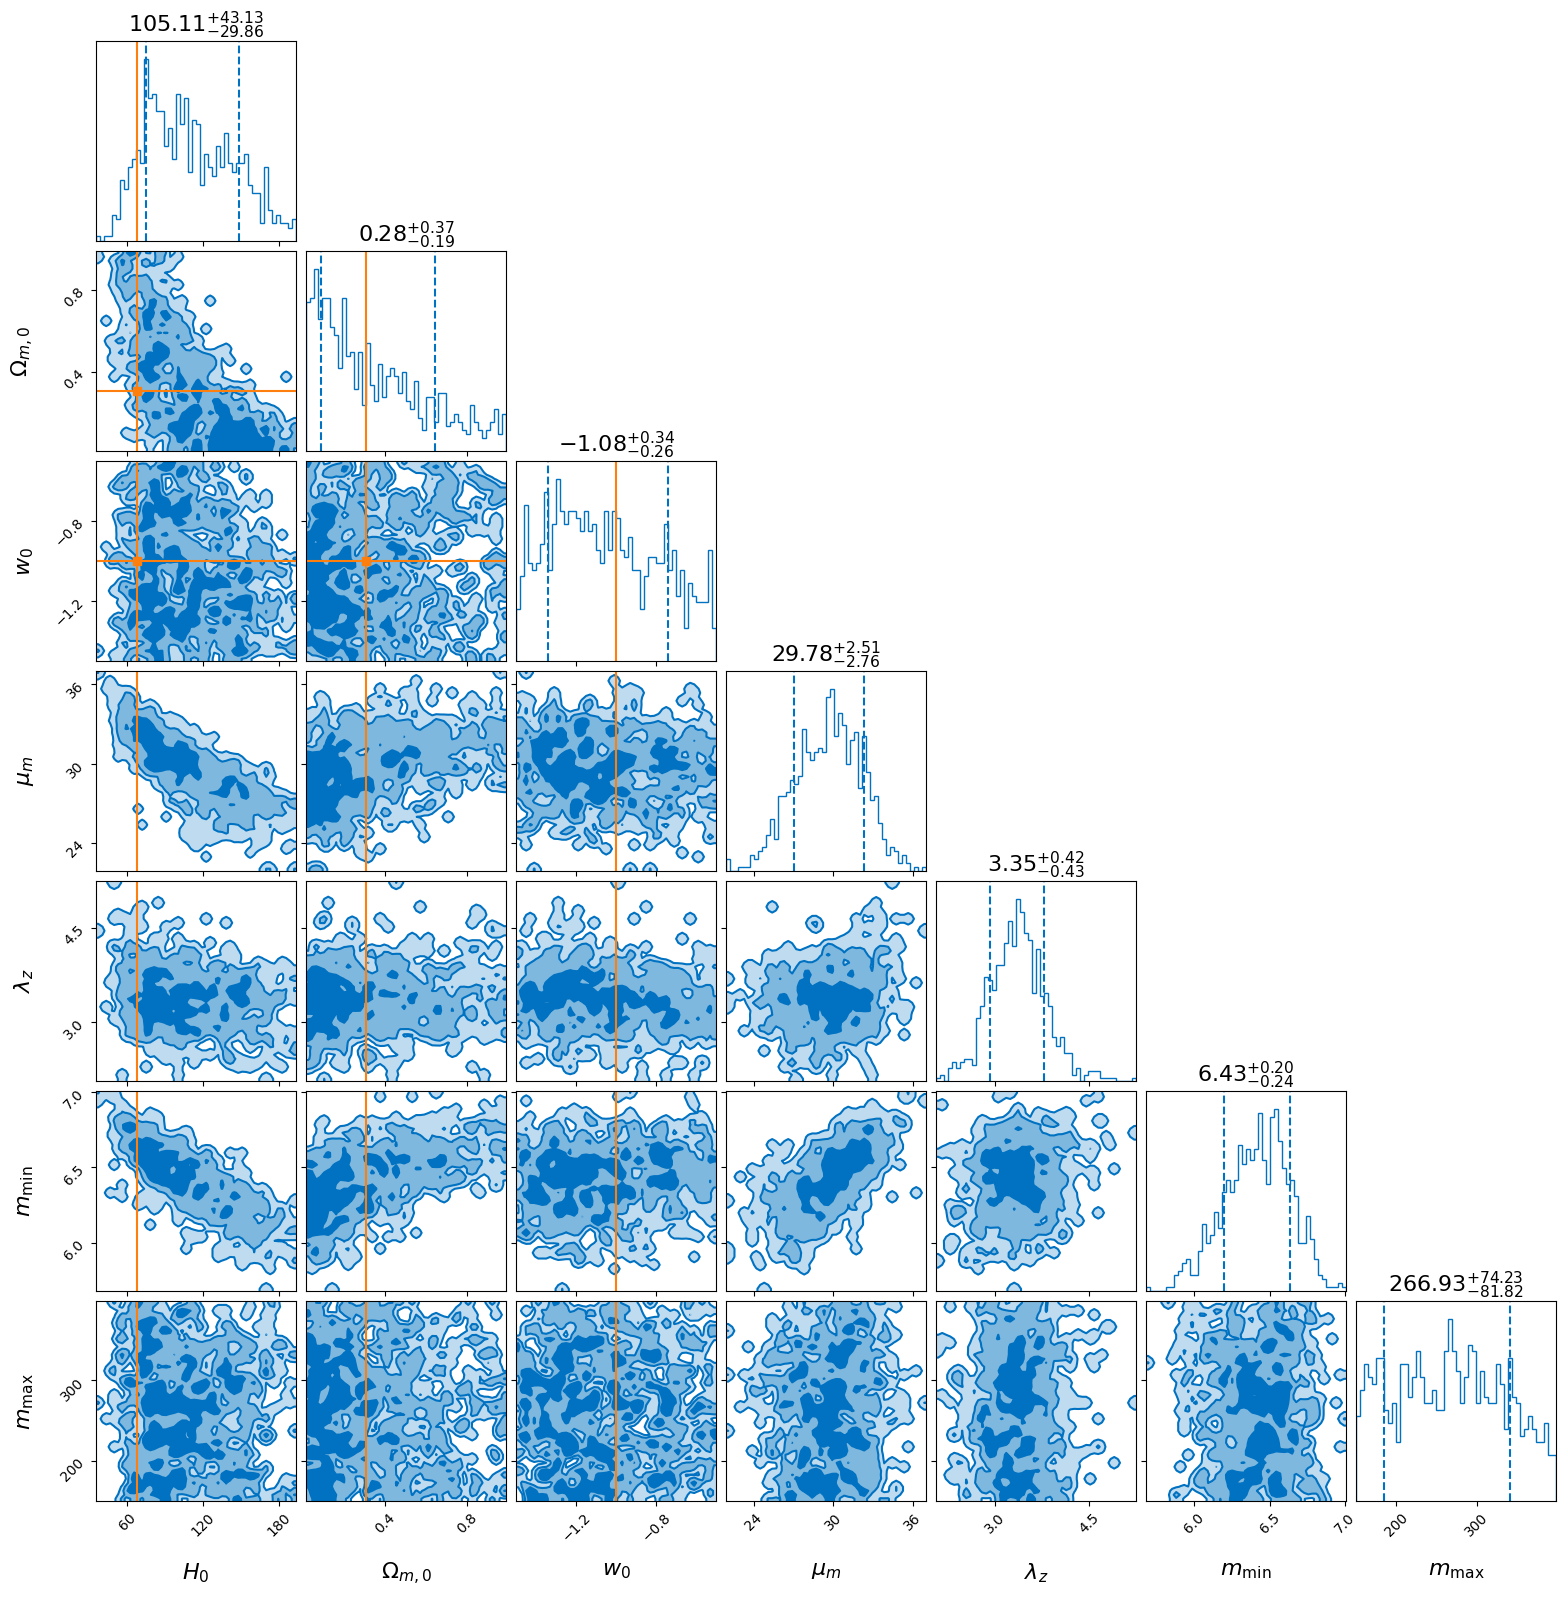

In [11]:
_ = result.plot_corner(
    save=False,
    parameters=["H0", "Om0", "w0", "mpp", "lamb", "mmin", "mmax"],
    truths=[67.74, 0.3075, -1, np.nan, np.nan, np.nan, np.nan],
)

How does this look?

How can we improve this result?

The first thing to check is that we aren't being significantly biased by systematic error in our likelihood estimates.
`GWPopulation` provides a build in way to evaluate the total variance due to Monte Carlo in addition to the contribution from each of the indidivual events.

In [12]:
import jax

func = jax.jit(likelihood.generate_extra_statistics)

full_posterior = pd.DataFrame([
    func(parameters) for parameters in result.posterior.to_dict(orient="records")
]).astype(float)
full_posterior.describe()

,H0,Om0,alpha,amax,beta,gaussian_mass_maximum,lam,lamb,ln_bf_0,ln_bf_1,...,var_93,var_94,var_95,var_96,var_97,var_98,var_99,variance,w0,xi_spin
count,824.000000,824.000000,824.000000,824.000000,824.000000,824.000000,824.000000,824.000000,824.000000,824.000000,...,824.000000,824.000000,824.000000,824.000000,824.000000,824.000000,824.000000,824.000000,824.000000,824.000000
mean,109.559572,0.343808,3.618599,0.865209,1.412699,152.417197,0.071120,3.357122,-10.865667,-10.350804,...,0.000462,0.002449,0.000554,0.002215,0.000149,0.015155,0.007395,1.244362,-1.049391,0.689279
std,33.890454,0.260071,0.190253,0.114556,0.757688,27.203545,0.022053,0.445089,0.900725,0.906733,...,0.000172,0.001412,0.000218,0.001566,0.000086,0.010807,0.004332,0.439179,0.265286,0.220681
min,35.736111,0.014776,2.894794,0.500125,-0.652484,100.429964,0.023695,2.059307,-14.559349,-13.882112,...,0.000124,0.000599,0.000148,0.000354,0.000017,0.002697,0.001094,0.446151,-1.499292,0.001630
25%,81.304285,0.120774,3.473736,0.811769,0.889850,130.277435,0.054370,3.058520,-11.410867,-10.915941,...,0.000343,0.001530,0.000403,0.001115,0.000088,0.008826,0.004643,0.944239,-1.267610,0.551461
50%,105.109535,0.276892,3.619946,0.895378,1.330516,154.366961,0.067919,3.353840,-10.793779,-10.245116,...,0.000428,0.002101,0.000507,0.001757,0.000131,0.012226,0.006432,1.165270,-1.077259,0.728313
75%,135.809643,0.513836,3.765707,0.953892,1.889389,175.144703,0.083622,3.637178,-10.253081,-9.722382,...,0.000543,0.002888,0.000663,0.002849,0.000195,0.017970,0.008947,1.447493,-0.827377,0.870902
max,193.480856,0.990720,3.998722,0.999863,4.171183,199.791808,0.155804,5.244113,-8.628697,-8.093594,...,0.001312,0.012419,0.001591,0.015071,0.000565,0.089086,0.036450,4.125405,-0.500003,0.999367


Now we have these values, we can visualize which variables are most strongly correlated with the variance and log likelihood and then make a corner plot including these variables.

In [13]:
full_posterior[result.search_parameter_keys + ["log_likelihood", "variance"]].corr()

,alpha,beta,mmin,mmax,lam,mpp,sigpp,gaussian_mass_maximum,amax,mu_chi,sigma_chi,mu_spin,xi_spin,sigma_spin,H0,Om0,w0,lamb,log_likelihood,variance
alpha,1.000000,0.276322,-0.114704,-0.026267,-0.196174,-0.233176,0.310826,-0.095041,0.192016,-0.048294,-0.108054,-0.093258,0.119649,-0.106757,0.183199,-0.073893,-0.071569,0.363809,0.138820,0.215163
beta,0.276322,1.000000,0.021073,-0.072025,-0.192093,-0.127015,0.147392,-0.019124,0.079309,-0.019376,-0.054663,-0.074484,0.040912,-0.072796,0.050574,-0.025569,0.053412,-0.190788,-0.024124,0.087811
mmin,-0.114704,0.021073,1.000000,-0.022950,-0.272784,0.651000,-0.104865,0.057878,-0.103069,0.035485,0.034321,0.117926,-0.095659,0.052393,-0.803447,0.544829,0.111351,0.153686,0.038166,0.161790
mmax,-0.026267,-0.072025,-0.022950,1.000000,-0.002384,0.059044,0.046985,0.118509,-0.032197,-0.047010,0.115934,-0.150955,0.140687,0.074620,-0.061639,-0.016878,-0.015069,0.024287,0.003024,-0.012251
lam,-0.196174,-0.192093,-0.272784,-0.002384,1.000000,-0.534252,0.528407,0.025585,-0.000019,-0.041266,-0.035978,-0.011949,-0.034991,0.080590,0.296276,-0.110702,0.171045,-0.365308,-0.300128,-0.188115
mpp,-0.233176,-0.127015,0.651000,0.059044,-0.534252,1.000000,-0.492216,-0.027234,-0.084746,0.054663,0.101338,0.114709,-0.028818,-0.011708,-0.777633,0.418582,-0.056205,0.140877,0.170062,0.085470
sigpp,0.310826,0.147392,-0.104865,0.046985,0.528407,-0.492216,1.000000,-0.031743,0.072321,-0.018232,-0.032391,-0.043853,-0.033922,0.071106,0.116592,-0.057945,0.026045,0.005967,-0.254435,-0.249879
gaussian_mass_maximum,-0.095041,-0.019124,0.057878,0.118509,0.025585,-0.027234,-0.031743,1.000000,-0.002147,-0.022606,-0.066026,0.148128,-0.072843,0.131381,-0.037018,0.098207,0.098042,-0.040785,-0.078844,-0.012932
amax,0.192016,0.079309,-0.103069,-0.032197,-0.000019,-0.084746,0.072321,-0.002147,1.000000,-0.235438,-0.577263,0.047979,0.158891,-0.236459,0.060721,-0.087279,0.019886,-0.043565,0.537096,-0.088632
mu_chi,-0.048294,-0.019376,0.035485,-0.047010,-0.041266,0.054663,-0.018232,-0.022606,-0.235438,1.000000,-0.113261,-0.081036,0.020722,-0.023408,-0.007542,-0.022215,-0.066886,-0.006635,-0.120670,-0.065090


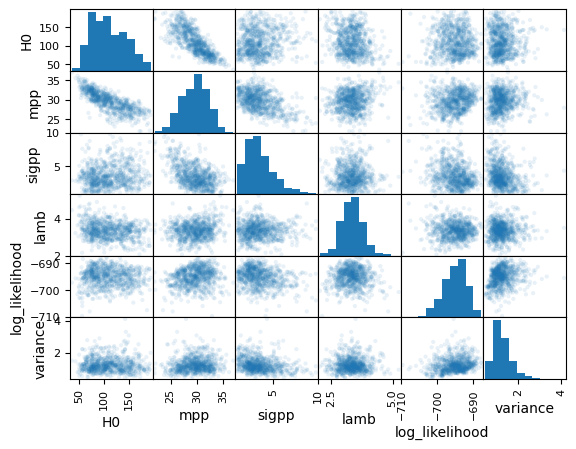

In [14]:
pd.plotting.scatter_matrix(
    full_posterior[["H0", "mpp", "sigpp", "lamb", "log_likelihood", "variance"]],
    alpha=0.1,
)
plt.show()
plt.close()

These look reasonable, all the variances are around one, which shouldn't cause signficant biases.

The next most likely candidate for poor recorvery of cosmological parameters is using an insufficient model for the astrophysical population (see, e.g., [Farah _et al._ (2404.02210)](https://arxiv.org/abs/2404.02210)).

**Challenge**: implement a more sophisticated model for the masses and see if it improves the measurement of cosmological parameters.

_hint_: see the most recent [LVK population paper](https://arxiv.org/pdf/2508.18083) for inspiration.